# **Assignment 2**

##### Author: Simen Roko Krogstie

#### Accounts


- My GitHub repo can be found [here](https://github.com/SimenKrogstie/D2D_SRK)
- My Streamlit app can be found [here](https://d2dsrk.streamlit.app/)
- My Screencast can be found [here](https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=97f13a03-029f-4376-9c31-b4e90133b4a1)

#### Imports

In [4]:
import os
import sys
import tomllib
import setuptools
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make the modules package in the repository root importable from the notebooks folder
REPO_ROOT = Path.cwd().parent
sys.path.append(str(REPO_ROOT))

from modules.data_flow import EntsoeClient, FlowRepository
from modules.data_loader import ReservoirClient
from modules.spark_cassandra import SparkCassandra

2026-10-20 19:25:00.063 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 19:25:00.063 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 19:25:00.063 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 19:25:00.064 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 19:25:00.065 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 19:25:00.065 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


#### Configuration and secrets
Secrets  are read from `.streamlit/secrets.toml`

In [5]:
with open(REPO_ROOT / ".streamlit" / "secrets.toml", "rb") as f:
    SECRETS = tomllib.load(f)

ENTSOE_TOKEN = SECRETS["entsoe"]["token"]
MONGO_URI = SECRETS["mongo"]["uri"]

SparkCassandra.configure_environment()
print("JAVA_HOME:", os.environ["JAVA_HOME"])

JAVA_HOME: /Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home


## NVE Magasinstatistikk API
The CSV file from part 1 is replaced by a direct connection to the NVE Magasinstatistikk API.
Relevant endpoints:
- `HentOffentligData`: the full weekly series for all areas (same columns as the old CSV file)
- `HentOmråder`: description of the areas used in the statistics

In [6]:
nve = ReservoirClient()

# Download all public reservoir data, the response is a JSON list with one object per area and week
df_raw = nve.fetch_raw()
print(df_raw.shape)
df_raw.head()

(14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


#### Areas covered by the API
The data is split in three area types:
- **EL**: the five electricity price areas NO1-NO5 (elspot areas)
- **NO**: Norway as a whole (national total, area number 0)
- **VASS**: watercourse areas (vassdragsområder)

In [7]:
# Print the area descriptions from the API
nve.fetch_areas_raw()

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

In [8]:
# Which area numbers exist for each area type in the data
df_raw.groupby("omrType")["omrnr"].unique()

omrType
EL      [4, 1, 3, 5, 2]
NO                  [0]
VASS          [2, 3, 1]
Name: omrnr, dtype: object

#### Rename columns and handle the time columns

In [9]:
df = ReservoirClient.preprocess(df_raw)
df.dtypes

date                     datetime64[us]
area_type                           str
area_number                       int64
iso_year                          int64
iso_week                          int64
fill_degree                     float64
capacity_twh                    float64
filling_twh                     float64
next_publish_date        datetime64[us]
fill_degree_prev_week           float64
change_in_fill_degree           float64
dtype: object

#### Plot each column separately

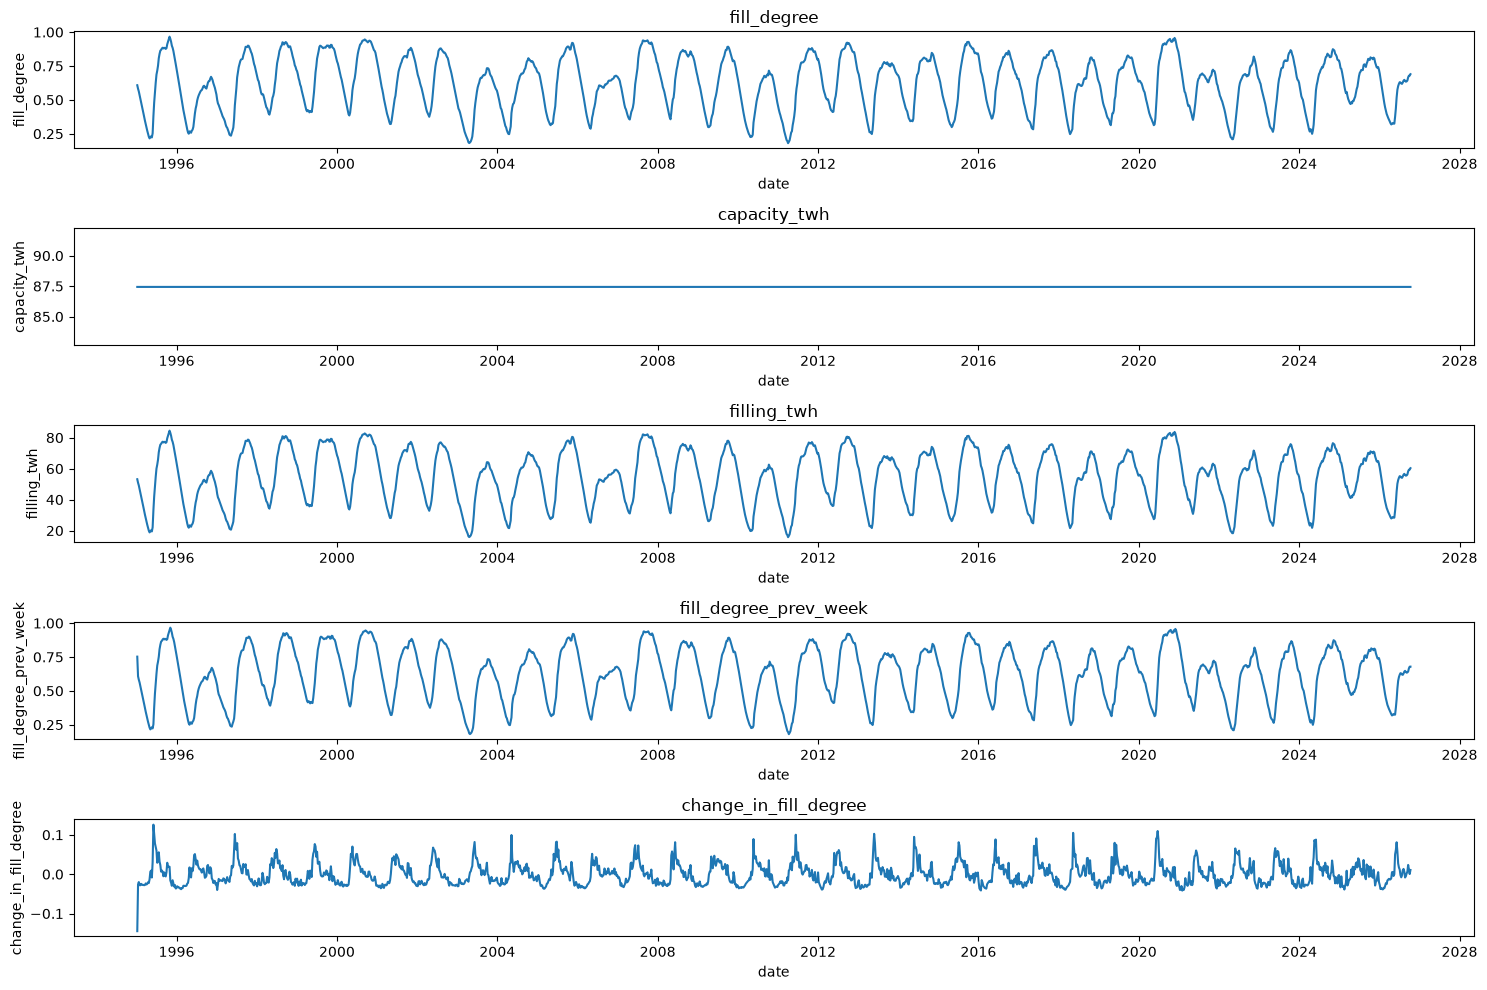

In [10]:
# Numeric columns that aren't identifiers
numeric_cols = ReservoirClient.VALUE_COLS

# National total only, as in part 1
df_no = (
    df.loc[df["area_type"] == "NO", ["date"] + numeric_cols]
    .set_index("date")
    .sort_index()
)

# Initialize a figure for plotting each column
fig, axes = plt.subplots(len(numeric_cols), figsize=(15, 10))

# Plotting each column in the figure
for col, ax in zip(df_no.columns, axes.ravel()):
    ax.plot(df_no.index, df_no[col])
    ax.set_title(col)
    ax.set_ylabel(col)
    ax.set_xlabel("date")

plt.tight_layout()
plt.show()

#### Plot all columns together

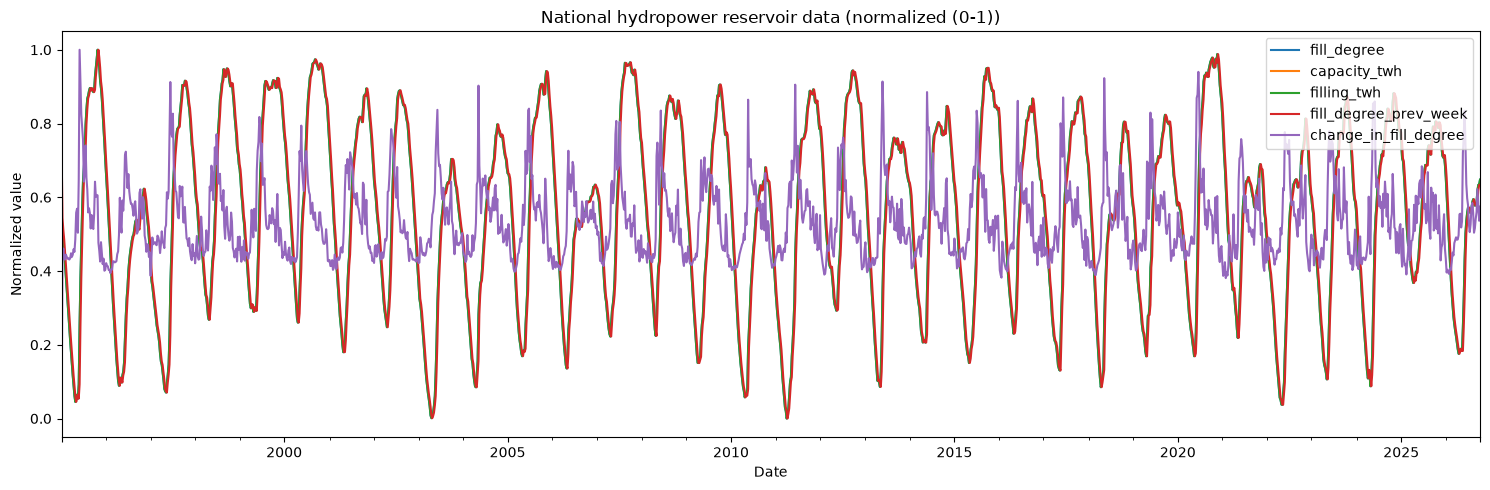

In [11]:
# Normalizing the columns in df_no such that they are comparable
df_norm = (df_no - df_no.min()) / (df_no.max() - df_no.min())

# Plotting the columns in one plot
df_norm.plot(figsize=(15, 5))
plt.title("National hydropower reservoir data (normalized (0-1))")
plt.xlabel("Date")
plt.ylabel("Normalized value")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## ENTSO-E API
Data is downloaded from the ENTSO-E Transparency Platform REST API
A connection is defined as a border between a Norwegian bidding zone and a neighbouring bidding zone. Both directions are downloaded for each connection.

In [12]:
# The connections and the EIC codes of their bidding zones
pd.DataFrame(
    [(f"{a}-{b}", EntsoeClient.ZONES[a], EntsoeClient.ZONES[b]) for a, b in EntsoeClient.CONNECTIONS],
    columns=["connection", "Norwegian zone EIC", "foreign zone EIC"],
)

,connection,Norwegian zone EIC,foreign zone EIC
0,NO1-SE3,10YNO-1--------2,10Y1001A1001A46L
1,NO3-SE2,10YNO-3--------J,10Y1001A1001A45N
2,NO4-SE1,10YNO-4--------9,10Y1001A1001A44P
3,NO4-SE2,10YNO-4--------9,10Y1001A1001A45N
4,NO4-FI,10YNO-4--------9,10YFI-1--------U
5,NO2-DK1,10YNO-2--------T,10YDK-1--------W
6,NO2-NL,10YNO-2--------T,10YNL----------L
7,NO2-DE_LU,10YNO-2--------T,10Y1001A1001A82H
8,NO2-GB,10YNO-2--------T,10YGB----------A


In [13]:
# The last two years, up to midnight today (UTC)
END = pd.Timestamp.now(tz="UTC").normalize()
START = END - pd.DateOffset(years=2)
print(START, "->", END)

2024-10-20 00:00:00+00:00 -> 2026-10-20 00:00:00+00:00


#### Download and parse

In [14]:
entsoe = EntsoeClient(ENTSOE_TOKEN)

# One row per connection, direction and hour
df_flows = entsoe.fetch_all(START, END)
print(df_flows.shape)
df_flows.head()

NO1 -> SE3: 17520 hours
SE3 -> NO1: 17520 hours
NO3 -> SE2: 17520 hours
SE2 -> NO3: 17520 hours
NO4 -> SE1: 17520 hours
SE1 -> NO4: 17520 hours
NO4 -> SE2: 17520 hours
SE2 -> NO4: 17520 hours
NO4 -> FI: 17520 hours
FI -> NO4: 17520 hours
NO2 -> DK1: 17520 hours
DK1 -> NO2: 17520 hours
NO2 -> NL: 17520 hours
NL -> NO2: 17520 hours
NO2 -> DE_LU: 17520 hours
DE_LU -> NO2: 17520 hours
NO2 -> GB: 17520 hours
GB -> NO2: 17520 hours
(315360, 8)


,connection,direction,from_zone,to_zone,time,flow_mw,energy_mwh,year
0,NO1-SE3,NO1 -> SE3,NO1,SE3,2024-10-20 00:00:00,0.0,0.0,2024
1,NO1-SE3,NO1 -> SE3,NO1,SE3,2024-10-20 01:00:00,0.0,0.0,2024
2,NO1-SE3,NO1 -> SE3,NO1,SE3,2024-10-20 02:00:00,0.0,0.0,2024
3,NO1-SE3,NO1 -> SE3,NO1,SE3,2024-10-20 03:00:00,0.0,0.0,2024
4,NO1-SE3,NO1 -> SE3,NO1,SE3,2024-10-20 04:00:00,0.0,0.0,2024


## Cassandra

In [15]:
store = SparkCassandra(host="localhost", port=9042)
store.create_schema()

# Check the connection by asking Cassandra for its version
print(store.session.execute("SELECT release_version FROM system.local").one())

Row(release_version='5.0.9')


## Spark
Spark is connected to Cassandra with the `spark-cassandra-connector`, pyspark 3.5.1 is used for compatibility with the connector. The Spark session time zone is set to UTC so timestamps are not shifted.

In [16]:
spark = store.start_spark()
spark

26/10/20 17:29:50 WARN Utils: Your hostname, Simen-sin-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.11.59 instead (on interface en0)
26/10/20 17:29:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/simenkrogstie/.ivy2/cache
The jars for the packages stored in: /Users/simenkrogstie/.ivy2/jars


:: loading settings :: url = jar:file:/Users/simenkrogstie/Documents/Programming/H26/D2D_SRK/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-7ed3caa1-3fda-4be5-a317-2a0a3b6acbda;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassand

#### Test the Spark-Cassandra connection

In [17]:
# Read the table to check that Spark can reach Cassandra
store.read().printSchema()

root
 |-- connection: string (nullable = false)
 |-- direction: string (nullable = true)
 |-- from_zone: string (nullable = true)
 |-- to_zone: string (nullable = true)
 |-- year: integer (nullable = false)
 |-- time: timestamp (nullable = true)
 |-- flow_mw: double (nullable = true)
 |-- energy_mwh: double (nullable = true)
 |-- month: integer (nullable = true)



#### Insert the ENTSO-E data into Cassandra using Spark

In [18]:
# The pandas DataFrame is converted to a Spark DataFrame and appended to the Cassandra table.
# Rows with the same primary key are overwritten, so re-running does not create duplicates
rows_written = store.write(df_flows)
print("Rows written:", rows_written)

/Users/simenkrogstie/Documents/Programming/H26/D2D_SRK/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:351: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  Cannot convert pyarrow.lib.ChunkedArray to pyarrow.lib.Array
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/20 17:29:57 WARN TaskSetManager: Stage 0 contains a task of very large size (2051 KiB). The maximum recommended task size is 1000 KiB.
26/10/20 17:29:59 WARN TaskSetManager: Stage 1 contains a task of very large size (2051 KiB). The maximum recommended task size is 1000 KiB.


Rows written: 315360


#### Extract relevant columns from Cassandra using Spark

In [19]:
# Spark selects the relevant columns and adds a month column, used for filtering in the app
sdf = store.read()
df_spark = sdf.toPandas()
print("Rows read:", len(df_spark))
df_spark.head()

Rows read: 315360


,connection,direction,from_zone,to_zone,year,time,flow_mw,energy_mwh,month
0,NO2-DE_LU,DE_LU -> NO2,DE_LU,NO2,2024,2024-10-20 00:00:00,0.0,0.0,10
1,NO2-DE_LU,DE_LU -> NO2,DE_LU,NO2,2024,2024-10-20 01:00:00,0.0,0.0,10
2,NO2-DE_LU,DE_LU -> NO2,DE_LU,NO2,2024,2024-10-20 02:00:00,0.0,0.0,10
3,NO2-DE_LU,DE_LU -> NO2,DE_LU,NO2,2024,2024-10-20 03:00:00,0.0,0.0,10
4,NO2-DE_LU,DE_LU -> NO2,DE_LU,NO2,2024,2024-10-20 04:00:00,0.0,0.0,10


In [20]:
# Number of hours per connection and direction, as a quick sanity check
sdf.groupBy("connection", "direction").count().orderBy("connection", "direction").show(truncate=False)

+----------+------------+-----+
|connection|direction   |count|
+----------+------------+-----+
|NO1-SE3   |NO1 -> SE3  |17520|
|NO1-SE3   |SE3 -> NO1  |17520|
|NO2-DE_LU |DE_LU -> NO2|17520|
|NO2-DE_LU |NO2 -> DE_LU|17520|
|NO2-DK1   |DK1 -> NO2  |17520|
|NO2-DK1   |NO2 -> DK1  |17520|
|NO2-GB    |GB -> NO2   |17520|
|NO2-GB    |NO2 -> GB   |17520|
|NO2-NL    |NL -> NO2   |17520|
|NO2-NL    |NO2 -> NL   |17520|
|NO3-SE2   |NO3 -> SE2  |17520|
|NO3-SE2   |SE2 -> NO3  |17520|
|NO4-FI    |FI -> NO4   |17520|
|NO4-FI    |NO4 -> FI   |17520|
|NO4-SE1   |NO4 -> SE1  |17520|
|NO4-SE1   |SE1 -> NO4  |17520|
|NO4-SE2   |NO4 -> SE2  |17520|
|NO4-SE2   |SE2 -> NO4  |17520|
+----------+------------+-----+



## Plots
#### Pie chart: total transfer for one year on a chosen connection
Each slice is the energy transferred in one direction, either in or out of Norway, during the year.

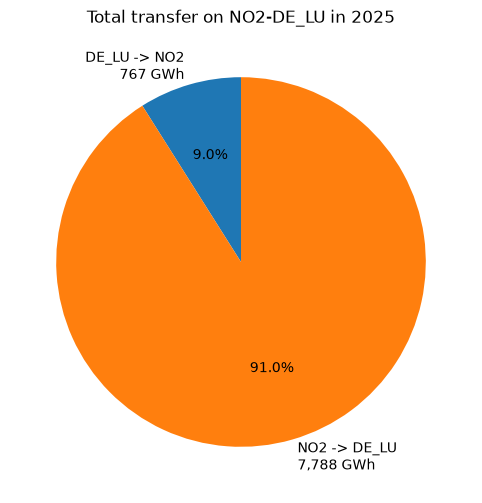

In [21]:
PIE_CONNECTION = "NO2-DE_LU"
PIE_YEAR = 2025

pie_df = df_spark[(df_spark["connection"] == PIE_CONNECTION) & (df_spark["year"] == PIE_YEAR)]

# Sum the hourly energy per direction and convert from MWh to GWh
totals_gwh = pie_df.groupby("direction")["energy_mwh"].sum() / 1000

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(totals_gwh, labels=[f"{d}\n{v:,.0f} GWh" for d, v in totals_gwh.items()], autopct="%1.1f%%", startangle=90)
ax.set_title(f"Total transfer on {PIE_CONNECTION} in {PIE_YEAR}")
plt.show()

#### Line plot: first month of a year for chosen connections
One line per connection and direction.

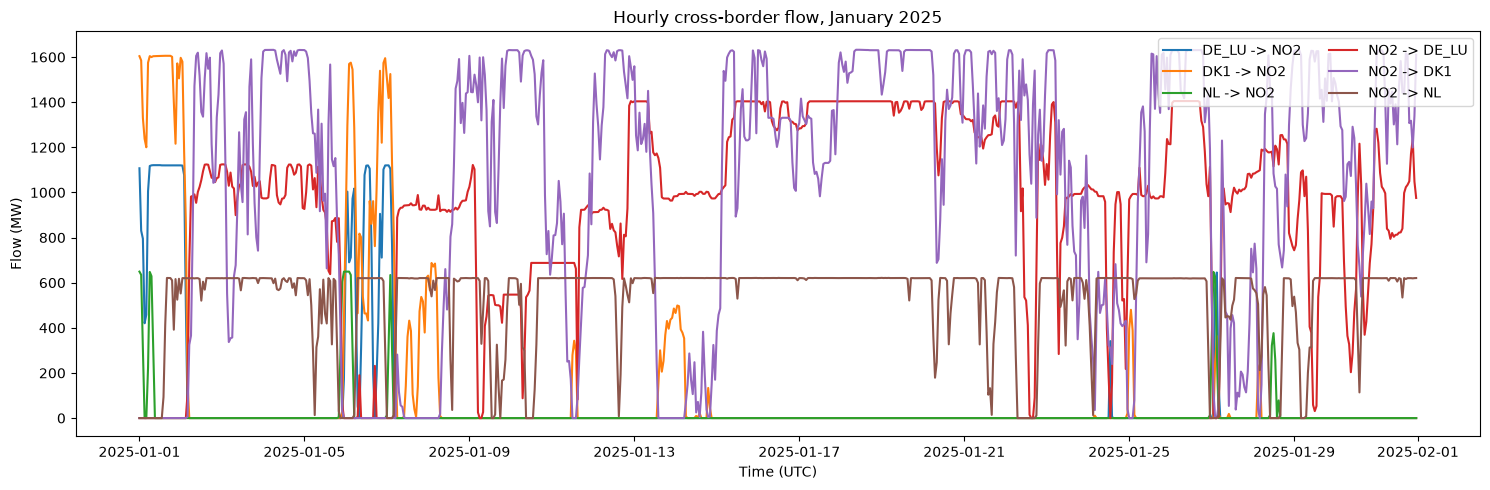

In [19]:
LINE_CONNECTIONS = ["NO2-DE_LU", "NO2-NL", "NO2-DK1"]
LINE_YEAR = 2025

line_df = df_spark[
    df_spark["connection"].isin(LINE_CONNECTIONS)
    & (df_spark["year"] == LINE_YEAR)
    & (df_spark["month"] == 1)
]

fig, ax = plt.subplots(figsize=(15, 5))
# The direction names include the zones, so they identify both the connection and the direction
for direction, group in line_df.sort_values("time").groupby("direction"):
    ax.plot(group["time"], group["flow_mw"], label=direction)

ax.set_title(f"Hourly cross-border flow, January {LINE_YEAR}")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Flow (MW)")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

## MongoDB
The data extracted with Spark is inserted into MongoDB Atlas where the Streamlit app reads it through the same `FlowRepository` class.
`replace_all` empties the collection before inserting, so re-running the notebook does not duplicate documents, and creates an index matching the queries in the app.

In [22]:
mongo = FlowRepository(MONGO_URI)
mongo.ping()  # Fails here if the URI or the IP access list is wrong

n_documents = mongo.replace_all(df_spark)
print("Documents in MongoDB:", n_documents, "| rows from Spark:", len(df_spark))

Documents in MongoDB: 315360 | rows from Spark: 315360


In [23]:
# Read back January for one connection, the same query the app makes
mongo.flows(PIE_CONNECTION, PIE_YEAR, months=(1,)).head()

,direction,time,flow_mw,energy_mwh,month
0,DE_LU -> NO2,2025-01-01 00:00:00,1107.1125,1107.1125,1
1,NO2 -> DE_LU,2025-01-01 00:00:00,0.0000,0.0000,1
2,DE_LU -> NO2,2025-01-01 01:00:00,830.5250,830.5250,1
3,NO2 -> DE_LU,2025-01-01 01:00:00,0.0000,0.0000,1
4,DE_LU -> NO2,2025-01-01 02:00:00,795.1600,795.1600,1


In [24]:
# Stop Spark and close the database connections
store.stop()
mongo.close()

## My git log

In [29]:
!git -C .. log --oneline -15

6065221 (HEAD -> main, origin/main, origin/HEAD) Merge pull request #6 from SimenKrogstie/dev
76c2e3c (origin/dev, dev) Merge branch 'main' of github.com:SimenKrogstie/D2D_SRK into dev
ed8b383 docs: Fixed typos
efc80eb Merge pull request #5 from SimenKrogstie/dev
750f559 docs: Fixed typo in comment
40f2e8d refactor: Updated home page with part 2 content
ffdd0f3 feat: shared sidebar with area type, month interval and column selector
504ea13 feat: Added cross-border flows page
126da43 refactor: Moved extra/contact page to page five
6b10a1e feat: Added Spark-Cassandra storage and extraction of the flows
bbba60c feat: Added ENTSO-E client and MongoDB repository for cross-border flows
84b806a feat: Repålaced the reservoir CSV with the NVE API in a new modules packaging
bf158b9 feat: Added .pdf-files
6f5f3ff feat: Added link to Screencast
31cd943 Merge pull request #4 from SimenKrogstie/dev


## Notes on development

Part 2 started with replacing the CSV file from part 1 by a direct connection to the NVE Magasinstatistikk API. `HentOffentligData` returns the same columns as the CSV, so the renaming from part 1 could be reused, and the experience with the time columns came in handy: `dato_Id` is the last day of an ISO week, and `neste_Publiseringsdato` uses `0001-01-01` as a placeholder that has to become a missing value. `HentOmråder` and the unique area numbers showed three area types: the five price areas (EL), the national total (NO) and the watercourse areas (VASS). The part 1 plots were recreated from the API data.

The larger part of the work was the ENTSO-E pipeline. I defined each connection as a border between a Norwegian and a foreign bidding zone and downloaded the cross-border physical flows (A11) in both directions for the last two years, split into yearly chunks since one request can cover at most one year. Parsing the XML needed some care: the namespace version varies, ENTSO-E changed from hourly to 15-minute resolution during 2025, and curve type A03 omits repeated values. I read the resolution per period, forward-filled missing positions and averaged everything to hourly values. Borders without data are skipped.

Cassandra runs in Docker and Spark connects to it through the spark-cassandra-connector. Getting Java 17 and pyspark 3.5.1 to work together was the most fiddly part. The Cassandra table is partitioned on connection and year, and writing the same data twice overwrites instead of duplicating it. Spark writes the data, then extracts the relevant columns and adds a month column before the data is plotted and inserted into MongoDB.

I also refactored the repository to a more object-oriented structure. The code shared by the notebook and the app lives in a `modules` package: `ReservoirClient` for the NVE API, `EntsoeClient` and `FlowRepository` for ENTSO-E and MongoDB, and `SparkCassandra` for the Cassandra and Spark steps. Each Streamlit page is a small class with a `render` method.

In the app, the reservoir table and plot pages share sidebar controls drawn from `app.py`, so the choices are kept when switching page: radio buttons for the area type and a slider deciding which interval is downloaded. Each new interval makes a new API request, and since `HentOffentligData` has no date parameters, the interval is cut out after downloading. The table shows one `LineChartColumn` sparkline per area and the plot one line per area. A new page reads the flows from MongoDB through a cached client, with a pie chart controlled by radio buttons and a year selector on the left, a line plot for any set of months chosen with pills on the right, and an expander documenting the data source. The MongoDB URI and ENTSO-E token are kept in `secrets.toml`, which is not on GitHub, and pasted into the app settings on streamlit.io.

Overall, this part gave practical experience with JSON and XML APIs, Cassandra with Spark, and serving data from a cloud database.

## Declaration of AI usage

This project is developed with the help of generative AI. The model used is Claude Opus 5.5 (via Claude Code). It has been used to debug code for the API calls, parsing XML, Spark-Cassandra connection and to look up git commands. It has also been used for helping to refactor the app to a more object-oriented structure. 